In [2]:
import pandas as pd
df2 = pd.read_csv("data/GSE103322_HNSCC_all_data.txt.gz", sep="\t", index_col=0)
print(df2.shape)
df2.iloc[:8, :3]

(23691, 5902)


/var/folders/cz/g79tq1ys47vd6t_tysfpfn4r0000gn/T/ipykernel_90291/769890629.py:2: DtypeWarning: Columns (1: HN28_P15_D06_S330_comb, 2: HN28_P6_G05_S173_comb, 4: HN26_P14_H05_S281_comb, 8: HN26_P25_A11_S107_comb, 11: HN25_P5_E10_S58_comb, 13: HN25_P25_C01_S313_comb, 14: HN28_P15_G06_S366_comb, 15: HN26_P6_B06_S18_comb, 16: HN25_P5_C05_S29_comb, 17: HN28_P6_D09_S141_comb, 19: HN26_P13_D07_S139_comb, 25: HN25_P5_E12_S60_comb, 27: HN25_P5_F01_S61_comb, 28: HN26_P5_D12_S48_comb, 29: HN25_P25_C11_S323_comb, 32: HN26_P5_G11_S83_comb, 33: HNSCC26_P12_G04_S268_comb, 34: HN25_P23_G05_S269_comb, 36: HN25_P25_F01_S349_comb, 39: HN25_P23_C01_S217_comb, 40: HN28_P6_A09_S105_comb, 41: HN25_P25_E06_S342_comb, 42: HN25_P23_H09_S285_comb, 43: HN28_P6_H07_S187_comb, 48: HNSCC26_P12_D11_S239_comb, 49: HN28_P6_B03_S111_comb, 51: HN25_P5_B06_S18_comb, 52: HN25_P5_B04_S16_comb, 54: HN25_P5_A05_S5_comb, 56: HNSCC26_P12_G11_S275_comb, 59: HNSCC26_P12_H11_S287_comb, 60: HN25_P24_F06_S162_comb, 61: HN26_P6_A08_S8

,HN28_P15_D06_S330_comb,HN28_P6_G05_S173_comb,HN26_P14_D11_S239_comb
processed by Maxima enzyme,1,1,1.00000
Lymph node,1,0,1.00000
classified as cancer cell,0,0,1.00000
classified as non-cancer cells,1,1,0.00000
non-cancer cell type,Fibroblast,Fibroblast,0.00000
'C9orf152',0,0,0.42761
'RPS11',6.0037,7.3006,7.28850
'ELMO2',0,0,0.00000


In [3]:
labels2 = df2.iloc[:5].T
labels2.columns = ["maxima", "lymph_node", "cancer", "normal", "cell_type"]

genes2 = df2.iloc[5:].astype(float)
genes2.index = genes2.index.str.strip("'")     # remove the quotes around gene names

print(genes2.shape)
pd.crosstab(labels2["cancer"].astype(float), labels2["normal"].astype(float))

(23686, 5902)


normal,0.0,1.0
cancer,,
0.0,324,3363
1.0,2215,0


In [4]:
labels2["cell_type"].value_counts()

cell_type
0.0            2539
Fibroblast     1422
T cell         1237
Endothelial     260
B cell          138
Mast            120
Macrophage       98
Dendritic        51
myocyte          19
-Fibroblast      18
Name: count, dtype: int64

In [5]:
odd = labels2[labels2["cell_type"] == "-Fibroblast"]
odd[["cancer", "normal", "lymph_node"]].astype(float).value_counts()

cancer  normal  lymph_node
0.0     1.0     0.0           16
                1.0            2
Name: count, dtype: int64

In [6]:
import anndata as ad 
import scanpy as sc
adata2 = ad.AnnData(X = genes2.T.values.astype("float32"))       # flip to cells x genes
adata2.obs_names = genes2.columns # cell names
adata2.var_names = genes2.index   # gene names
adata2.var_names_make_unique()   # some gene names repeat; this adds -1, -2 to duplicates

for col in ["maxima", "lymph_node", "cancer", "normal", "cell_type"]:
    adata2.obs[col] = labels2[col].values

adata2

AnnData object with n_obs × n_vars = 5902 × 23686
    obs: 'maxima', 'lymph_node', 'cancer', 'normal', 'cell_type'
    layers: None (.X)

In [7]:
import numpy as np
c = adata2.obs["cancer"].astype(float)
nm = adata2.obs["normal"].astype(float)

adata2.obs["malignant"] = np.where(c == 1, "2", np.where(nm == 1, "1", "0"))
adata2.obs["malignant"].value_counts()

malignant
1    3363
2    2215
0     324
Name: count, dtype: int64

In [8]:
adata2.obs["tumor"] = adata2.obs_names.str.split("_").str[0]
adata2.obs["tumor"].value_counts()



tumor
HNSCC20    691
HNSCC16    596
HNSCC18    567
HNSCC25    501
HNSCC17    490
HNSCC5     370
HN28       355
HNSCC6     308
HNSCC      282
HNSCC28    261
HN25       224
HN26       214
HNSCC26    214
HNSCC22    201
HNSCC12    157
HNSCC24    130
HNSCC8     104
HNSCC13     90
HNSCC10     89
HN23        51
HNSCC7       7
Name: count, dtype: int64

In [9]:
pd.crosstab(adata2.obs["tumor"], adata2.obs["lymph_node"].astype(float))

lymph_node,0.0,1.0
tumor,,
HN23,51,0
HN25,98,126
HN26,71,143
HN28,227,128
HNSCC,259,23
HNSCC10,89,0
HNSCC12,157,0
HNSCC13,90,0
HNSCC16,596,0


In [10]:
adata2.obs["tumor"] = adata2.obs["tumor"].str.replace(r"^HN(\d)", r"HNSCC\1", regex=True)
adata2.obs["tumor"].nunique()

18

In [11]:
sc.pp.highly_variable_genes(adata2, n_top_genes=2000)

markers = ["PTPRC", "CD3E", "CD19", "CD14", "PECAM1", "COL1A1", "KRT5", "KRT14", "KRT17"]
markers = [g for g in markers if g in adata2.var_names]
adata2.var.loc[markers, "highly_variable"] = True

print(len(markers), adata2.var["highly_variable"].sum())

9 2007


In [12]:
adata2_hv = adata2[:, adata2.var["highly_variable"]].copy()
sc.pp.pca(adata2_hv, n_comps=50)
sc.pp.neighbors(adata2_hv)
sc.tl.umap(adata2_hv)

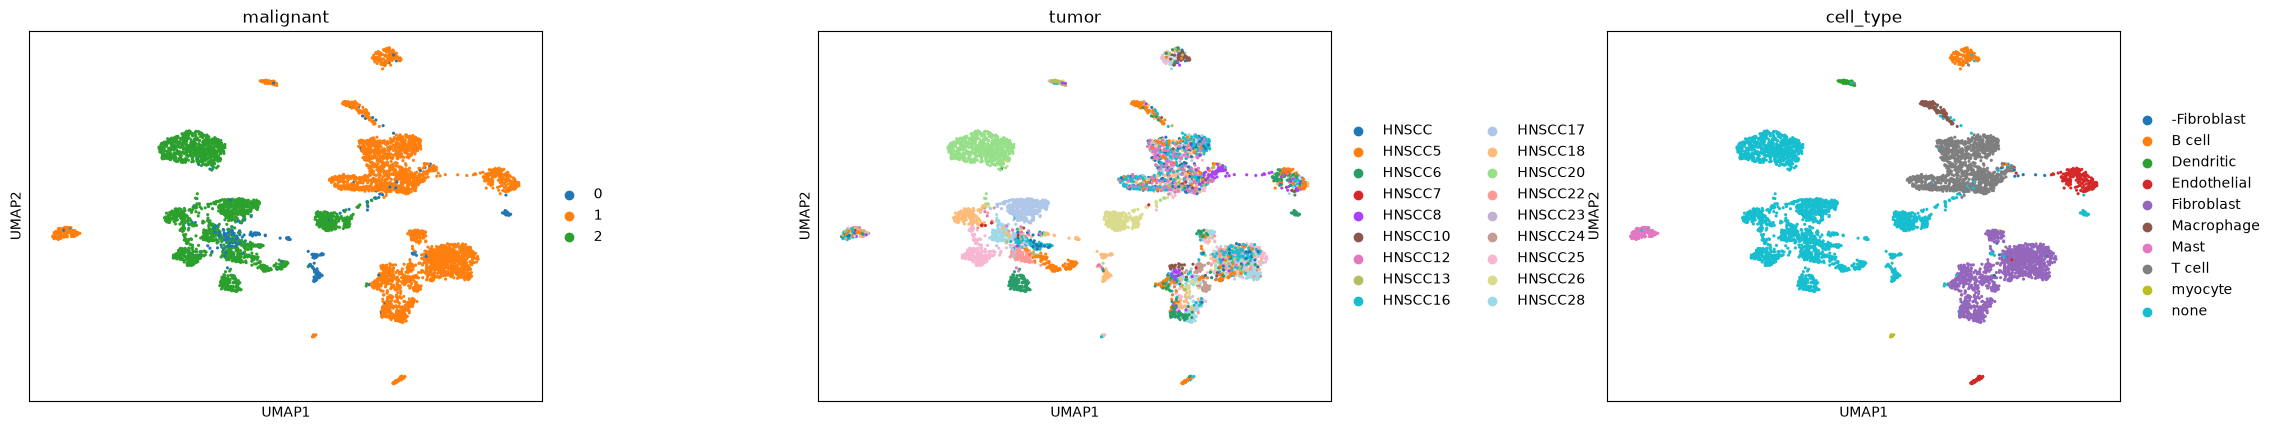

In [13]:
ct = adata2_hv.obs["cell_type"].astype(str).replace({"0.0": "none", "0": "none"})
adata2_hv.obs["cell_type"] = ct.astype("category")
adata2_hv.obs["cell_type"].value_counts()

sc.pl.umap(adata2_hv, color=["malignant", "tumor", "cell_type"], wspace=0.4)

In [14]:
from sklearn.model_selection import train_test_split
train2_idx, test2_idx = train_test_split(adata2_hv.obs_names, test_size=0.5,                               random_state=42, stratify=adata2_hv.obs["cell_type"])

print(len(train2_idx), len(test2_idx))


2951 2951


In [15]:
train2 = adata2_hv[train2_idx].copy()
train2 = train2[train2.obs["malignant"] != "0"].copy()      # drop unresolved
sc.tl.rank_genes_groups(train2, groupby="malignant", method="wilcoxon")
top_cancer2 = sc.get.rank_genes_groups_df(train2, group="2").head(8)
top_normal2 = sc.get.rank_genes_groups_df(train2, group="1").head(8)
candidates2 = list(top_cancer2["names"]) + list(top_normal2["names"])
candidates2

['KRT5',
 'KRT17',
 'KRT14',
 'KRT6C',
 'SLC7A8',
 'KRT16',
 'ATP1B1',
 'KRT6B',
 'ADAMTS4',
 'LYZ',
 'SLC4A8',
 'MAP1LC3C',
 'PCDH11X',
 'CCL22',
 'PTPRC',
 'IL12RB1']

In [16]:
expr2 = train2[:, candidates2].X
corr2 = np.corrcoef(expr2.T)

y2 = (train2.obs["malignant"] == "2").astype(int).values
r2 = np.array([abs(np.corrcoef(expr2[:, i], y2)[0, 1]) for i in range(len(candidates2))])

print(np.round(corr2[:6, :6], 2))

[[1.   0.9  0.9  0.7  0.71 0.72]
 [0.9  1.   0.82 0.71 0.7  0.63]
 [0.9  0.82 1.   0.74 0.7  0.75]
 [0.7  0.71 0.74 1.   0.47 0.74]
 [0.71 0.7  0.7  0.47 1.   0.43]
 [0.72 0.63 0.75 0.74 0.43 1.  ]]


In [17]:
for g, v in sorted(zip(candidates2, r2), key=lambda t: -t[1]):
    print(f"{g:10s} {v:.2f}")

KRT5       0.96
KRT17      0.92
KRT14      0.86
SLC7A8     0.72
KRT16      0.65
KRT6B      0.64
KRT6C      0.63
ATP1B1     0.55
PTPRC      0.43
ADAMTS4    0.34
MAP1LC3C   0.33
LYZ        0.28
PCDH11X    0.26
IL12RB1    0.24
SLC4A8     0.19
CCL22      0.17


In [18]:
n = len(candidates2)
k, alpha, lam = 2, 1.0, 2.0
R2 = np.clip(corr2, 0, None); np.fill_diagonal(R2, 0)
Q2 = np.zeros((n, n))
Q2 += alpha * R2 / 2
Q2 += lam * (np.ones((n, n)) - np.eye(n))
Q2[np.diag_indices(n)] += -r2 + lam * (1 - 2 * k)
const = lam * k**2

In [22]:
import itertools

best_score, best_x = np.inf, None
for bits in itertools.product([0,1], repeat=n):
    x = np.array(bits)
    score = x @ Q2 @ x + const
    if score < best_score:
        best_score, best_x = score, x

    chosen = [candidates2[i] for i in range(n) if best_x[i] == 1]
print("best score:", round(best_score, 3), " chosen genes:", chosen)


best score: -1.391  chosen genes: ['KRT5', 'PTPRC']


In [27]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score
test = adata2_hv[test2_idx].copy(); test = test[test.obs["malignant"] != "0"].copy()
y_test2 = (test.obs["malignant"] == "2").astype(int).values
def evaluate2(panel):
    model = LogisticRegression().fit(train2[:, panel].X, y2)
    pred = model.predict(test[:, panel].X)
    return balanced_accuracy_score(y_test2, pred)

In [28]:
print("QUBO  KRT5 + PTPRC:", round(evaluate2(["KRT5", "PTPRC"]), 3))
print("Top-2 KRT5 + KRT17:", round(evaluate2(["KRT5", "KRT17"]), 3))
print("Only  KRT5:        ", round(evaluate2(["KRT5"]), 3))

QUBO  KRT5 + PTPRC: 0.989
Top-2 KRT5 + KRT17: 0.995
Only  KRT5:         0.989


In [31]:
from qiskit.quantum_info import SparsePauliOp

Qm, c0 = Q2, const

terms = []
offset = c0
for i in range(n):
    terms.append(("Z", [i], -Qm[i, i] / 2))
    offset += Qm[i, i] / 2
    for j in range(n):
        if i != j:
            terms.append(("ZZ", [i, j], Qm[i, j] / 4))
            terms.append(("Z", [i], -Qm[i, j] / 4))
            terms.append(("Z", [j], -Qm[i, j] / 4))
            offset += Qm[i, j] / 4

H2 = SparsePauliOp.from_sparse_list(terms, num_qubits=n).simplify()
diag2 = H2.to_matrix(sparse=True).diagonal().real
best2 = np.argmin(diag2)

print(len(H2), "terms")
print("lowest energy:", round(diag2[best2] + offset, 3))
print("genes:", [candidates2[i] for i in range(n) if (best2 >> i) & 1])

136 terms
lowest energy: -1.391
genes: ['KRT5', 'PTPRC']


In [35]:
import time
from qiskit import transpile
from qiskit.circuit.library import QAOAAnsatz
from qiskit.quantum_info import Statevector

qaoa_h = QAOAAnsatz(H2, reps=1)
qc_h = transpile(qaoa_h, basis_gates=["h", "rz", "rx", "cx"])

def avg_energy_h(beta, gamma):
    psi = Statevector(qc_h.assign_parameters([beta, gamma]))
    return psi.probabilities() @ diag2 + offset

betas = np.linspace(0, np.pi/2, 25)
gammas = np.linspace(0, 0.5, 25)
energy_h = np.zeros((25, 25))
for a, g in enumerate(gammas):
    for b, bt in enumerate(betas):
        energy_h[a, b] = avg_energy_h(bt, g)

a, b = np.unravel_index(energy_h.argmin(), energy_h.shape)
probs_h = Statevector(qc_h.assign_parameters([betas[b], gammas[a]])).probabilities()
sizes = np.array([bin(x).count("1") for x in range(2**n)])

print("best avg energy:", energy_h[a, b].round(3), " β =", betas[b].round(3), " γ =", gammas[a].round(3))
print("P(best panel):", probs_h[best2].round(5))
print("P(2 genes):", probs_h[sizes == 2].sum().round(4))

best avg energy: 55.574  β = 0.327  γ = 0.167
P(best panel): 0.00014
P(2 genes): 0.0172


In [36]:
from scipy.optimize import minimize

qc_h2 = transpile(QAOAAnsatz(H2, reps=2), basis_gates=["h", "rz", "rx", "cx"])

def avg_energy_h2(angles):
    return Statevector(qc_h2.assign_parameters(angles)).probabilities() @ diag2 + offset

start = [betas[b], betas[b], gammas[a], gammas[a]]     # β0, β1, γ0, γ1
res_h = minimize(avg_energy_h2, start, method="COBYLA", options={"maxiter": 200})
probs_h2 = Statevector(qc_h2.assign_parameters(res_h.x)).probabilities()

print("best avg energy:", res_h.fun.round(3), " angles:", res_h.x.round(3))
print("P(best panel):", probs_h2[best2].round(5))
print("P(2 genes):", probs_h2[sizes == 2].sum().round(4))

best avg energy: 51.194  angles: [0.29  0.184 0.16  1.274]
P(best panel): 0.00058
P(2 genes): 0.0713
